In [1]:
# ==========================================
# 1. IMPORT LIBRARY
# ==========================================
import pandas as pd
import math
from collections import Counter
from nltk.util import bigrams, trigrams, ngrams

In [2]:
# ==========================================
# 2. LOAD DATASET
# ==========================================
df = pd.read_csv("dataset_preprocessed.csv")
text_column = "processed_text"

df = df.dropna(subset=[text_column])
print(f"Jumlah dokumen: {len(df)}")

Jumlah dokumen: 9803


In [3]:
# ==========================================
# 3. CORPUS TOKEN
# ==========================================
documents = [str(text).split() for text in df[text_column] if str(text).strip()]
tokens = [token for document in documents for token in document]

print(f"Total token: {len(tokens)}")
print(f"Contoh token: {tokens[:20]}")

Total token: 114046
Contoh token: ['bang', 'kumis', 'milik', 'karakter', 'salesman', 'yg', 'kuat', 'ciri', 'khas', 'ulang', 'unggul', 'produk', 'yg', 'jual', 'bukti', 'gagal', 'dng', 'tanam', 'dlm', 'pikir']


In [7]:
# ==========================================
# 4.UNIGRAM FREQUENCY
# ==========================================
unigram = Counter(tokens)

print("20 Kata Paling Sering Muncul:")
for word, count in unigram.most_common(20):
    print(f"  {word:<20} : {count}")

20 Kata Paling Sering Muncul:
  mbg                  : 4133
  yg                   : 3417
  makan                : 2353
  anak                 : 1488
  program              : 1302
  nya                  : 1245
  rakyat               : 1093
  racun                : 1005
  orang                : 993
  aja                  : 972
  sekolah              : 943
  gratis               : 865
  korupsi              : 824
  uang                 : 771
  gak                  : 730
  ya                   : 652
  gizi                 : 626
  kerja                : 600
  ga                   : 579
  negara               : 560


In [8]:
# ==========================================
# 5. PROBABILITAS UNIGRAM
# ==========================================
total_tokens = sum(unigram.values())

unigram_probability = {
    word: count / total_tokens
    for word, count in unigram.items()
}

print("\n10 Kata dengan Probabilitas Tertinggi:")
sorted_prob = sorted(
    unigram_probability.items(),
    key=lambda x: x[1],
    reverse=True
)
for word, prob in sorted_prob[:10]:
    print(f"  {word:<20} : {prob:.6f}")


10 Kata dengan Probabilitas Tertinggi:
  mbg                  : 0.036240
  yg                   : 0.029962
  makan                : 0.020632
  anak                 : 0.013047
  program              : 0.011416
  nya                  : 0.010917
  rakyat               : 0.009584
  racun                : 0.008812
  orang                : 0.008707
  aja                  : 0.008523


In [9]:
# ==========================================
# 6. MEMBUAT BIGRAM
# ==========================================
bigram_tokens = [
    pair
    for document in documents
    for pair in bigrams(document)
]
bigram_frequency = Counter(bigram_tokens)
bigram_context_frequency = Counter(word1 for word1, _ in bigram_tokens)

print("20 Bigram Paling Sering Muncul:")
for bigram, count in bigram_frequency.most_common(20):
    print(f"  {' '.join(bigram):<30} : {count}")

20 Bigram Paling Sering Muncul:
  orang tua                      : 313
  program mbg                    : 298
  makan gizi                     : 228
  makan gratis                   : 171
  anak anak                      : 155
  mbg makan                      : 151
  makan racun                    : 148
  stop mbg                       : 136
  dapur mbg                      : 132
  mbg yg                         : 119
  makan mbg                      : 118
  yg racun                       : 113
  anak sekolah                   : 112
  racun gratis                   : 112
  gizi gratis                    : 110
  mbg nya                        : 95
  program yg                     : 91
  ladang korupsi                 : 91
  mbg program                    : 90
  didik gratis                   : 88


In [10]:
# ==========================================
# 7. MEMBUAT TRIGRAM
# ==========================================
trigram_tokens = [
    trigram
    for document in documents
    for trigram in trigrams(document)
]
trigram_frequency = Counter(trigram_tokens)

print("20 Trigram Paling Sering Muncul:")
for trigram, count in trigram_frequency.most_common(20):
    print(f"  {' '.join(trigram):<40} : {count}")

20 Trigram Paling Sering Muncul:
  makan gizi gratis                        : 96
  makan racun gratis                       : 96
  mbg makan racun                          : 56
  orang tua murid                          : 35
  orang tua nya                            : 31
  biar orang tua                           : 29
  mbg makan gizi                           : 27
  orang tua yg                             : 25
  kasih orang tua                          : 25
  mbg ladang korupsi                       : 24
  orang tua siswa                          : 23
  buka lapang kerja                        : 23
  makan siang gratis                       : 21
  makan basi gratis                        : 19
  gizi gratis makan                        : 18
  program makan gizi                       : 18
  mbg makan basi                           : 15
  cipta lapang kerja                       : 14
  henti program mbg                        : 14
  hukum mati koruptor                      : 13


In [11]:
# ==========================================
# 8. CONDITIONAL PROBABILITY BIGRAM
# ==========================================
def bigram_probability(word1, word2):
    numerator = bigram_frequency[(word1, word2)]
    denominator = bigram_context_frequency[word1]

    if denominator == 0:
        return 0.0

    return numerator / denominator

# Gunakan bigram paling sering yang benar-benar muncul di dataset
(word1, word2), pair_count = bigram_frequency.most_common(1)[0]
prob = bigram_probability(word1, word2)
print(f"Bigram: ({word1}, {word2}) | Frekuensi: {pair_count}")
print(f"P({word2} | {word1}) = {prob:.6f}")

Bigram: (orang, tua) | Frekuensi: 313
P(tua | orang) = 0.324352


In [12]:
# ==========================================
# 9. PROBABILITAS KALIMAT
# ==========================================
def sentence_probability(sentence):
    words = sentence.lower().split()
    if not words:
        return 0.0

    probability = unigram_probability.get(words[0], 0.0)
    for i in range(len(words) - 1):
        p = bigram_probability(words[i], words[i + 1])
        probability *= p

    return probability

# Uji lima rangkaian minimal lima kata yang paling sering muncul di dataset
fivegram_frequency = Counter(
    gram
    for document in documents
    for gram in ngrams(document, 5)
)
test_sentences = [
    " ".join(words)
    for words, _ in fivegram_frequency.most_common(5)
]

for sentence in test_sentences:
    p = sentence_probability(sentence)
    print(f"Jumlah kata: {len(sentence.split())}")
    print(f"P('{sentence}') = {p:.8e}")

Jumlah kata: 5
P('makan gizi gratis makan racun') = 1.48037014e-06
Jumlah kata: 5
P('gizi gratis makan racun gratis') = 5.18213987e-07
Jumlah kata: 5
P('mbg makan gizi gratis mbg') = 1.05615729e-06
Jumlah kata: 5
P('makan gizi gratis mbg makan') = 6.01291582e-07
Jumlah kata: 5
P('gizi gratis mbg makan racun') = 1.03839933e-07


In [13]:
# ==========================================
# 10. LAPLACE SMOOTHING BIGRAM
# ==========================================
unknown_token = "<UNK>"
vocabulary = set(unigram)
vocab_size = len(vocabulary) + 1  
def smoothed_bigram_probability(word1, word2):
    word1 = word1 if word1 in vocabulary else unknown_token
    word2 = word2 if word2 in vocabulary else unknown_token

    numerator = bigram_frequency[(word1, word2)] + 1
    denominator = bigram_context_frequency[word1] + vocab_size
    return numerator / denominator

# Uji bigram paling sering dari dataset
word1, word2 = bigram_frequency.most_common(1)[0][0]
prob = smoothed_bigram_probability(word1, word2)
print(f"Smoothed P({word2} | {word1}) = {prob:.8f}")

# Uji pasangan yang salah satu katanya mungkin di luar vocabulary
word1, word2 = "deep", "learning"
mapped_word1 = word1 if word1 in vocabulary else unknown_token
mapped_word2 = word2 if word2 in vocabulary else unknown_token
prob = smoothed_bigram_probability(word1, word2)
print(f"Input ({word1}, {word2}) dipetakan menjadi ({mapped_word1}, {mapped_word2})")
print(f"Smoothed P({mapped_word2} | {mapped_word1}) = {prob:.8f}")

Smoothed P(tua | orang) = 0.01933736
Input (deep, learning) dipetakan menjadi (deep, <UNK>)
Smoothed P(<UNK> | deep) = 0.00006547


In [14]:
# ==========================================
# 11. PREDIKSI KATA BERIKUTNYA
# ==========================================
def predict_next_word(context_word, top_n=5):
    context_word = context_word.lower()
    if context_word not in vocabulary or bigram_context_frequency[context_word] == 0:
        return []

    candidates = [
        (word, smoothed_bigram_probability(context_word, word))
        for word in vocabulary | {unknown_token}
    ]
    candidates.sort(key=lambda item: (-item[1], item[0]))
    return candidates[:top_n]

# Uji prediksi untuk lima context word yang paling sering muncul
context_words = [
    word for word, _ in bigram_context_frequency.most_common(5)
]

for context in context_words:
    predictions = predict_next_word(context)
    print(f"\nPrediksi kata setelah '{context}':")
    if predictions:
        for word, prob in predictions:
            print(f"  {word:<20} : {prob:.6f}")
    else:
        print("Konteks tidak ditemukan sebagai awal bigram di dataset.")


Prediksi kata setelah 'mbg':
  makan                : 0.008026
  yg                   : 0.006336
  nya                  : 0.005069
  program              : 0.004805
  henti                : 0.004594

Prediksi kata setelah 'yg':
  racun                : 0.006119
  masak                : 0.003704
  makan                : 0.003274
  tdk                  : 0.002684
  sdh                  : 0.001986

Prediksi kata setelah 'makan':
  gizi                 : 0.013069
  gratis               : 0.009816
  racun                : 0.008503
  mbg                  : 0.006791
  yg                   : 0.004851

Prediksi kata setelah 'anak':
  anak                 : 0.009355
  sekolah              : 0.006776
  yg                   : 0.004737
  bangsa               : 0.003538
  racun                : 0.003178

Prediksi kata setelah 'program':
  mbg                  : 0.018083
  yg                   : 0.005564
  makan                : 0.003326
  perintah             : 0.001875
  bagus                : 0.0

In [15]:
# ==========================================
# 12. PERPLEXITY
# ==========================================
def perplexity(probability, N):
    if probability is None or probability <= 0 or N <= 0:
        return float("inf")
    return probability ** (-1 / N)

def smoothed_sentence_probability(sentence):
    words = sentence.lower().split()
    if not words:
        return 0.0

    first_word = words[0] if words[0] in vocabulary else unknown_token
    probability = (unigram[first_word] + 1) / (sum(unigram.values()) + vocab_size)
    for i in range(len(words) - 1):
        probability *= smoothed_bigram_probability(words[i], words[i + 1])
    return probability

# Hitung perplexity untuk setiap kalimat uji pada sel 9
for sentence in test_sentences:
    prob = smoothed_sentence_probability(sentence)
    N = len(sentence.split())
    pp = perplexity(prob, N)
    print(f"Kalimat : '{sentence}'")
    print(f"P(W)    : {prob:.8e}")
    print(f"N       : {N}")
    print(f"PP(W)   : {pp:.4f}\n")

Kalimat : 'makan gizi gratis makan racun'
P(W)    : 3.37939120e-11
N       : 5
PP(W)   : 124.2317

Kalimat : 'gizi gratis makan racun gratis'
P(W)    : 4.83030513e-12
N       : 5
PP(W)   : 183.3180

Kalimat : 'mbg makan gizi gratis mbg'
P(W)    : 3.68525574e-11
N       : 5
PP(W)   : 122.0974

Kalimat : 'makan gizi gratis mbg makan'
P(W)    : 2.09847412e-11
N       : 5
PP(W)   : 136.6530

Kalimat : 'gizi gratis mbg makan racun'
P(W)    : 3.63676707e-12
N       : 5
PP(W)   : 194.0246



In [56]:
# ==========================================
# 13. ANALISIS ZERO PROBABILITY
# ==========================================
# Cari bigram yang tidak pernah muncul, tetapi kedua katanya ada di vocabulary
zero_context, zero_next = next(
    (context, candidate)
    for context, _ in bigram_context_frequency.most_common()
    for candidate in sorted(vocabulary)
    if (context, candidate) not in bigram_frequency
)
zero_sentence = f"{zero_context} {zero_next}"

raw_probability = sentence_probability(zero_sentence)
smoothed_probability = smoothed_sentence_probability(zero_sentence)
print(f"Bigram tidak terlihat: ({zero_context}, {zero_next})")
print(f"P({zero_next} | {zero_context}) tanpa smoothing = {bigram_probability(zero_context, zero_next):.8f}")
print(f"P(kalimat) tanpa smoothing = {raw_probability:.8f}")
print(f"P(kalimat) dengan Laplace smoothing = {smoothed_probability:.8e}")
print("Tanpa smoothing, satu bigram yang tidak terlihat membuat probabilitas seluruh kalimat menjadi nol.")

Bigram tidak terlihat: (mbg, aa)
P(aa | mbg) tanpa smoothing = 0.00000000
P(kalimat) tanpa smoothing = 0.00000000
P(kalimat) dengan Laplace smoothing = 1.68791701e-06
Tanpa smoothing, satu bigram yang tidak terlihat membuat probabilitas seluruh kalimat menjadi nol.


In [16]:
# ==========================================
# 14. Perbandingan Unigram, Bigram, Trigram
# ==========================================
print("=" * 60)
print("PERBANDINGAN MODEL N-GRAM")
print("=" * 60)
print(f"Ukuran Vocabulary     : {len(unigram):,}")
print(f"Jumlah Token          : {len(tokens):,}")
print(f"Jumlah Unigram unik   : {len(unigram):,}")
print(f"Jumlah Bigram unik    : {len(bigram_frequency):,}")
print(f"Jumlah Trigram unik   : {len(trigram_frequency):,}")
print()

# Cek sparsity
max_unigram = len(unigram)
max_bigram = len(unigram) ** 2
max_trigram = len(unigram) ** 3
print(f"Kemungkinan Unigram maks : {max_unigram:,}")
print(f"Unigram coverage         : {len(unigram)/max_unigram*100:.4f}%")
print(f"Kemungkinan Bigram maks  : {max_bigram:,}")
print(f"Bigram yang ada          : {len(bigram_frequency):,}")
print(f"Bigram coverage          : {len(bigram_frequency)/max_bigram*100:.4f}%")
print(f"Kemungkinan Trigram maks : {max_trigram:,}")
print(f"Trigram yang ada         : {len(trigram_frequency):,}")
print(f"Trigram coverage         : {len(trigram_frequency)/max_trigram*100:.8f}%")

PERBANDINGAN MODEL N-GRAM
Ukuran Vocabulary     : 15,272
Jumlah Token          : 114,046
Jumlah Unigram unik   : 15,272
Jumlah Bigram unik    : 73,800
Jumlah Trigram unik   : 90,249

Kemungkinan Unigram maks : 15,272
Unigram coverage         : 100.0000%
Kemungkinan Bigram maks  : 233,233,984
Bigram yang ada          : 73,800
Bigram coverage          : 0.0316%
Kemungkinan Trigram maks : 3,561,949,403,648
Trigram yang ada         : 90,249
Trigram coverage         : 0.00000253%


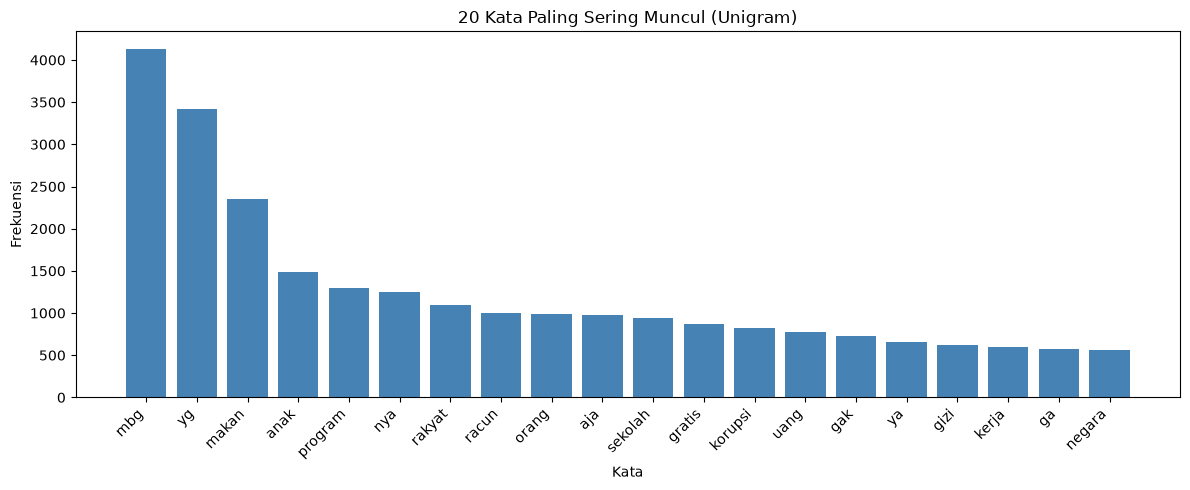

In [17]:
import matplotlib.pyplot as plt

# Top 20 unigram
top_words = unigram.most_common(20)
words_list = [w[0] for w in top_words]
counts_list = [w[1] for w in top_words]

plt.figure(figsize=(12, 5))
plt.bar(words_list, counts_list, color="steelblue")
plt.xticks(rotation=45, ha="right")
plt.xlabel("Kata")
plt.ylabel("Frekuensi")
plt.title("20 Kata Paling Sering Muncul (Unigram)")
plt.tight_layout()
plt.show()

## E. Analisis dan Perbandingan

| Model | Konteks | Kelebihan | Kekurangan |
|---|---|---|---|
| Unigram | 1 kata (frekuensi kata saja) | Sederhana dan cepat dihitung | Tidak mempertimbangkan urutan atau konteks kata |
| Bigram | 1 kata sebelumnya untuk memprediksi kata berikutnya | Menangkap hubungan lokal antarkata | Konteks pendek; pasangan yang tidak terlihat butuh smoothing |
| Trigram | 2 kata sebelumnya untuk memprediksi kata berikutnya | Konteks lebih kaya | Lebih sparse dan membutuhkan lebih banyak data |

### Keterbatasan N-Gram

1. **Sparsity** — banyak kombinasi kata tidak muncul di korpus. Pada dataset ini, bigram yang teramati hanya sebagian kecil dari seluruh kombinasi vocabulary; coverage yang dihitung di atas sekitar 0,0316%.
2. **Konteks terbatas** — bigram hanya memakai satu kata sebelumnya, sedangkan trigram memakai dua kata sebelumnya.
3. **Tidak memahami makna** — model mengandalkan frekuensi dan urutan kata, bukan makna atau kemiripan semantik.
4. **Vocabulary besar** — jumlah kombinasi yang mungkin meningkat tajam saat ukuran vocabulary atau nilai N bertambah.